In [284]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [285]:
df = pd.read_csv("social_media_engagement_5000.csv")

In [286]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [287]:
df.head

<bound method NDFrame.head of       user_id   age  gender    country  post_id post_type post_category  \
0       25795  43.0  Female     Brazil   496713     image       fitness   
1       10860  33.0    Male     Brazil   157326      reel          food   
2       86820  32.0  Female         UK   109864      text          food   
3       64886  51.0   Other     France   848877      text       fitness   
4       16265  34.0   Other         UK   449706     image       fitness   
...       ...   ...     ...        ...      ...       ...           ...   
4995    59500  44.0    Male  Australia   441541     video     education   
4996    22100  38.0   Other        UAE   677076      reel     education   
4997    67021  63.0  Female        USA   273595      text        travel   
4998    29800  13.0  Female    Germany   785644     video       fitness   
4999    73400  54.0   Other      Japan   712252      text        travel   

        likes  comments  shares  watch_time_sec  impression_count   p

In [288]:
df["posted_at"]=pd.to_datetime(df["posted_at"],format="%d-%m-%y",errors="coerce")
print(df["posted_at"].dtypes)

datetime64[s]


In [289]:
likes_array=np.array(df["likes"])
print("maximum_likes:",np.nanmax(likes_array))
print("minimum_likes:",np.nanmin(likes_array))
print("average_likes:",np.nanmean(likes_array))
print("total_likes:",np.nansum(likes_array))
print("shape:",likes_array.shape)
print("size:",likes_array.size)

maximum_likes: 19998.0
minimum_likes: 10.0
average_likes: 10107.043711340206
total_likes: 49019162.0
shape: (5000,)
size: 5000


In [290]:
df.isnull().sum()

user_id                0
age                  150
gender               150
country                0
post_id                0
post_type              0
post_category          0
likes                150
comments             150
shares               150
watch_time_sec         0
impression_count       0
posted_at           5000
follower_count         0
is_verified            0
device_type            0
sentiment            150
hashtags               0
engagement_rate        0
dtype: int64

In [291]:
df.isna().sum().sum()

np.int64(5900)

In [292]:
df["age"] = df["age"].fillna(df["age"].median())
df["likes"] = df["likes"].fillna(df["likes"].median())
df["shares"] = df["shares"].fillna(df["shares"].median())
df["comments"] = df["comments"].fillna(df["comments"].median())
df["gender"] = df["gender"].fillna(df["gender"].mode()[0])
df["sentiment"] = df["sentiment"].fillna(df["sentiment"].mode()[0])
df["posted_at"] = df["posted_at"].ffill().bfill()

In [293]:
df.isnull().sum()

user_id                0
age                    0
gender                 0
country                0
post_id                0
post_type              0
post_category          0
likes                  0
comments               0
shares                 0
watch_time_sec         0
impression_count       0
posted_at           5000
follower_count         0
is_verified            0
device_type            0
sentiment              0
hashtags               0
engagement_rate        0
dtype: int64

In [294]:
df.duplicated().sum()

np.int64(0)

In [295]:
df = df.drop_duplicates()

In [296]:
df["age"] = df["age"].astype(int)
df["is_verified"] = df["is_verified"].astype(bool)

In [297]:
df["gender"] = df["gender"].str.strip().str.lower()
df["post_type"] = df["post_type"].str.strip().str.lower()
df["post_category"] = df["post_category"].str.strip().str.lower()
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df["device_type"] = df["device_type"].str.strip().str.lower()
df["country"] = df["country"].str.strip()

In [298]:
df[["likes", "comments", "shares", "watch_time_sec",
    "impression_count", "follower_count"]].describe()

,likes,comments,shares,watch_time_sec,impression_count,follower_count
count,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000.000000
mean,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,393698.224800
std,5702.293017,856.393312,570.8552,2308.096459,28844.939104,230927.884535
min,10.000000,0.000000,0.0000,0.000000,105.000000,87.000000
25%,5235.000000,792.000000,511.0000,2017.750000,24988.250000,194480.000000
50%,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,388982.000000
75%,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,589744.250000
max,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,799533.000000


In [299]:
metrics = ["likes", "comments", "shares", "watch_time_sec","impression_count", "follower_count"]
for col in metrics:
    print(col, (df[col] < 0).sum())

likes 0
comments 0
shares 0
watch_time_sec 0
impression_count 0
follower_count 0


In [300]:
for col in metrics:
    df.loc[df[col] < 0, col] = np.nan
    df[col] = df[col].fillna(df[col].median())

In [301]:
df["hashtag_count"] = df["hashtags"].str.count("#")
df["sentiment"] = df["sentiment"].str.lower().str.strip()
df["sentiment"].unique()
df.isnull().sum().sum()
df.shape

(5000, 20)

In [302]:
df.head()
df.tail()
df.shape
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [303]:
df.info()
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype        
---  ------            --------------  -----        
 0   user_id           5000 non-null   int64        
 1   age               5000 non-null   int64        
 2   gender            5000 non-null   str          
 3   country           5000 non-null   str          
 4   post_id           5000 non-null   int64        
 5   post_type         5000 non-null   str          
 6   post_category     5000 non-null   str          
 7   likes             5000 non-null   float64      
 8   comments          5000 non-null   float64      
 9   shares            5000 non-null   float64      
 10  watch_time_sec    5000 non-null   float64      
 11  impression_count  5000 non-null   float64      
 12  posted_at         0 non-null      datetime64[s]
 13  follower_count    5000 non-null   float64      
 14  is_verified       5000 non-null   bool         
 15

user_id                     int64
age                         int64
gender                        str
country                       str
post_id                     int64
post_type                     str
post_category                 str
likes                     float64
comments                  float64
shares                    float64
watch_time_sec            float64
impression_count          float64
posted_at           datetime64[s]
follower_count            float64
is_verified                  bool
device_type                   str
sentiment                     str
hashtags                      str
engagement_rate           float64
hashtag_count               int64
dtype: object

In [304]:
df.describe()
df.describe(include="all")

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000,5000,5000.000000,5000,5000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,0,5000.000000,5000,5000,5000,5000,5000.000000,5000.000000
unique,NaN,NaN,3,10,NaN,4,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,3,3,761,NaN,NaN
top,NaN,NaN,male,India,NaN,reel,fitness,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,mobile,positive,#tech,NaN,NaN
freq,NaN,NaN,1849,535,NaN,1283,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4517,1684,2513,201,NaN,NaN
mean,54561.890800,38.440400,NaN,NaN,548042.909000,NaN,NaN,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,NaT,393698.224800,NaN,NaN,NaN,NaN,0.964356,1.998600
min,10055.000000,13.000000,NaN,NaN,100068.000000,NaN,NaN,10.000000,0.000000,0.0000,0.000000,105.000000,NaT,87.000000,NaN,NaN,NaN,NaN,0.006363,1.000000
25%,32309.500000,26.000000,NaN,NaN,322543.500000,NaN,NaN,5235.000000,792.000000,511.0000,2017.750000,24988.250000,NaT,194480.000000,NaN,NaN,NaN,NaN,0.145781,1.000000
50%,54374.500000,38.000000,NaN,NaN,548077.500000,NaN,NaN,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,NaT,388982.000000,NaN,NaN,NaN,NaN,0.253896,2.000000
75%,77180.500000,51.000000,NaN,NaN,771574.500000,NaN,NaN,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,NaT,589744.250000,NaN,NaN,NaN,NaN,0.504794,3.000000
max,99963.000000,64.000000,NaN,NaN,999455.000000,NaN,NaN,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,NaT,799533.000000,NaN,NaN,NaN,NaN,191.504348,3.000000


In [305]:
df["gender"].value_counts()
df["post_type"].value_counts()
df["country"].unique()
df["country"].nunique()
df["sentiment"].value_counts()

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

In [306]:
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()
correlation

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [307]:
df.groupby("post_type")["likes"].mean()
df.groupby("country")["impression_count"].mean()
df.groupby("post_category")["likes"].sum()
df.groupby("sentiment")["engagement_rate"].mean()
df.groupby("device_type")["shares"].sum()

device_type
desktop    1674709.0
mobile     1673034.0
tablet     1666810.0
Name: shares, dtype: float64

In [308]:
df["engagement_score"] = (df["likes"] + df["comments"] + df["shares"])
df["hashtag_count"] = df["hashtags"].str.count("#")
df["year"] = df["posted_at"].dt.year
df["month"] = df["posted_at"].dt.month
df["day"] = df["posted_at"].dt.day

In [309]:
post_analysis = df.groupby("post_type").agg({
    "likes": "mean",
    "comments": "mean",
    "shares": "mean",
    "engagement_rate": "mean"
})
post_analysis

,likes,comments,shares,engagement_rate
post_type,,,,
image,10104.865277,1525.235766,1019.289495,0.895646
reel,10037.802416,1504.187062,982.042089,0.783047
text,10100.148193,1499.106024,1013.989558,1.064549
video,10188.600000,1479.160000,996.834286,1.122365


In [310]:
country_analysis = df.groupby("country").agg({
    "likes": "sum",
    "impression_count": "sum",
    "engagement_rate": "mean"
})
country_analysis

,likes,impression_count,engagement_rate
country,,,
Australia,5075003.5,23834767.0,1.324339
Brazil,4982891.5,24793360.0,1.540704
Canada,5162353.0,24984716.0,0.916659
France,5144946.5,25656926.0,1.146402
Germany,4963924.5,23816649.0,0.759000
India,5329920.5,28067377.0,0.655005
Japan,4761943.0,23418816.0,0.769623
UAE,5144426.0,24610992.0,1.112352
UK,4898275.5,25201861.0,0.850966


In [311]:
sentiment_analysis = df.groupby("sentiment").agg({
    "likes": "mean",
    "comments": "mean",
    "shares": "mean",
    "engagement_rate": "mean"
})
sentiment_analysis

,likes,comments,shares,engagement_rate
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,1.038486
neutral,9923.194499,1528.404060,996.565160,0.991170
positive,10180.062077,1480.650617,1005.086749,0.919744


In [312]:
top_posts = df.sort_values(by="engagement_score",ascending=False).head(10)
top_posts

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,year,month,day
41,90038,29,male,UK,147547,video,food,19918.0,2859.0,1903.0,...,False,desktop,negative,#tech #fun #foodie,0.333631,3,24680.0,NaN,NaN,NaN
1632,36660,36,male,Brazil,641620,image,food,19986.0,2930.0,1667.0,...,False,mobile,positive,#lifestyle #tech #music,0.453452,3,24583.0,NaN,NaN,NaN
3814,90360,43,female,UAE,943395,video,food,19920.0,2741.0,1848.0,...,False,tablet,positive,#lifestyle #fun #travel,0.382929,3,24509.0,NaN,NaN,NaN
3223,92909,19,male,India,182790,video,food,19871.0,2804.0,1811.0,...,False,tablet,negative,#fitness #lifestyle,0.449986,2,24486.0,NaN,NaN,NaN
2998,65267,14,male,Canada,462928,reel,music,19877.0,2921.0,1625.0,...,False,tablet,neutral,#music #foodie,0.269397,2,24423.0,NaN,NaN,NaN
1605,52534,52,female,USA,716963,text,fashion,19981.0,2621.0,1781.0,...,False,tablet,positive,#music #travel,0.940920,2,24383.0,NaN,NaN,NaN
3741,81354,60,male,Canada,422233,video,lifestyle,19877.0,2419.0,1943.0,...,False,tablet,negative,#music,2.305841,1,24239.0,NaN,NaN,NaN
2198,78011,25,female,USA,647678,reel,tech,19884.0,2505.0,1832.0,...,False,tablet,positive,#reels,0.287186,1,24221.0,NaN,NaN,NaN
4495,71744,51,male,France,160384,text,tech,19713.0,2509.0,1981.0,...,False,mobile,positive,#tech #fun #reels,0.330443,3,24203.0,NaN,NaN,NaN
1164,85520,49,male,UAE,594285,video,education,19560.0,2577.0,1968.0,...,False,tablet,positive,#foodie,50.640756,1,24105.0,NaN,NaN,NaN


In [313]:
df[df["likes"] > 10000]
df[df["is_verified"] == True]
df[df["sentiment"] == "positive"]

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,year,month,day
2,86820,32,female,UK,109864,text,food,4862.0,344.0,955.0,...,False,tablet,positive,#foodie,0.137345,1,6161.0,NaN,NaN,NaN
5,92386,16,other,Canada,174310,video,tech,12535.0,1790.0,99.0,...,False,desktop,positive,#fitness,0.579440,1,14424.0,NaN,NaN,NaN
11,51090,32,male,Australia,538701,image,travel,19856.0,1723.0,905.0,...,False,desktop,positive,#fun #fashion #love,12.381057,3,22484.0,NaN,NaN,NaN
12,77221,64,male,Canada,183557,text,music,8432.0,2883.0,495.0,...,False,desktop,positive,#fitness,0.131343,1,11810.0,NaN,NaN,NaN
13,74820,25,male,Brazil,287460,text,fashion,15700.0,1434.0,1886.0,...,False,desktop,positive,#foodie #lifestyle,48.894602,2,19020.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4988,35805,24,male,UAE,872112,image,education,17606.0,89.0,546.0,...,True,desktop,positive,#love,0.361738,1,18241.0,NaN,NaN,NaN
4989,21874,59,male,USA,189299,reel,fitness,5019.0,2588.0,414.0,...,False,tablet,positive,#travel #foodie,0.087365,2,8021.0,NaN,NaN,NaN
4995,59500,44,male,Australia,441541,video,education,16210.0,2013.0,1837.0,...,False,mobile,positive,#travel #fun,0.466761,2,20060.0,NaN,NaN,NaN
4997,67021,63,female,USA,273595,text,travel,13487.0,1497.0,167.0,...,False,desktop,positive,#lifestyle #tech,0.679688,2,15151.0,NaN,NaN,NaN


In [314]:
stats_cols = [
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "engagement_rate",
    "follower_count"
]

In [315]:
df[stats_cols].mean()
df[stats_cols].median()
df[stats_cols].mode().iloc[0]

likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64

In [316]:
df[stats_cols].std()
df[stats_cols].var()

likes              3.251615e+07
comments           7.334095e+05
shares             3.258757e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64

In [317]:
df[stats_cols].quantile([0.25, 0.50, 0.75])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5235.0,792.00,511.0,2017.75,0.145781,194480.00
0.50,10105.5,1497.00,1012.0,4034.50,0.253896,388982.00
0.75,14959.0,2235.25,1483.0,6020.25,0.504794,589744.25


In [318]:
df[stats_cols].describe()

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
count,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000.000000
mean,10106.997400,1502.039800,1002.9106,4014.503200,0.964356,393698.224800
std,5702.293017,856.393312,570.8552,2308.096459,5.318029,230927.884535
min,10.000000,0.000000,0.0000,0.000000,0.006363,87.000000
25%,5235.000000,792.000000,511.0000,2017.750000,0.145781,194480.000000
50%,10105.500000,1497.000000,1012.0000,4034.500000,0.253896,388982.000000
75%,14959.000000,2235.250000,1483.0000,6020.250000,0.504794,589744.250000
max,19998.000000,2999.000000,1999.0000,7998.000000,191.504348,799533.000000


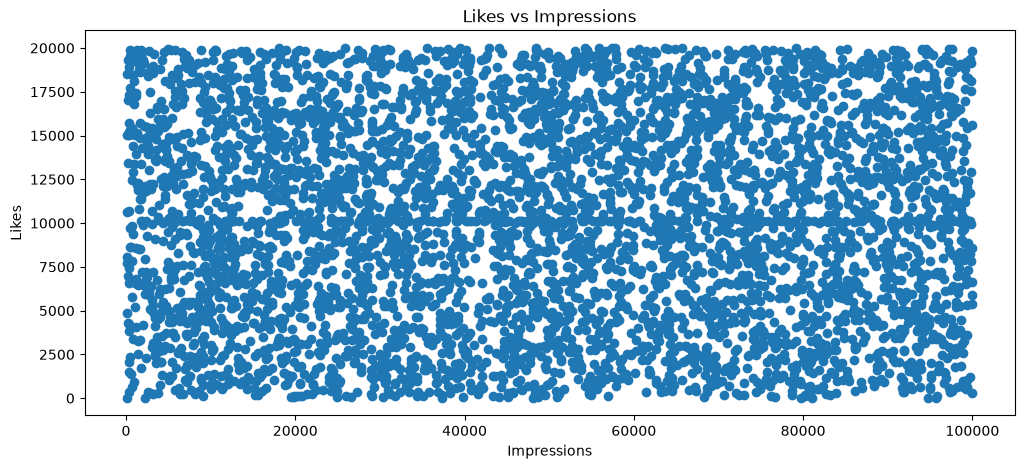

In [319]:
plt.figure(figsize=(12,5))
plt.scatter(df["impression_count"], df["likes"])
plt.title("Likes vs Impressions")
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.show()

INSIGHTS

The points form a shapeless cloud (correlation 0.01), so more impressions do not bring more likes.

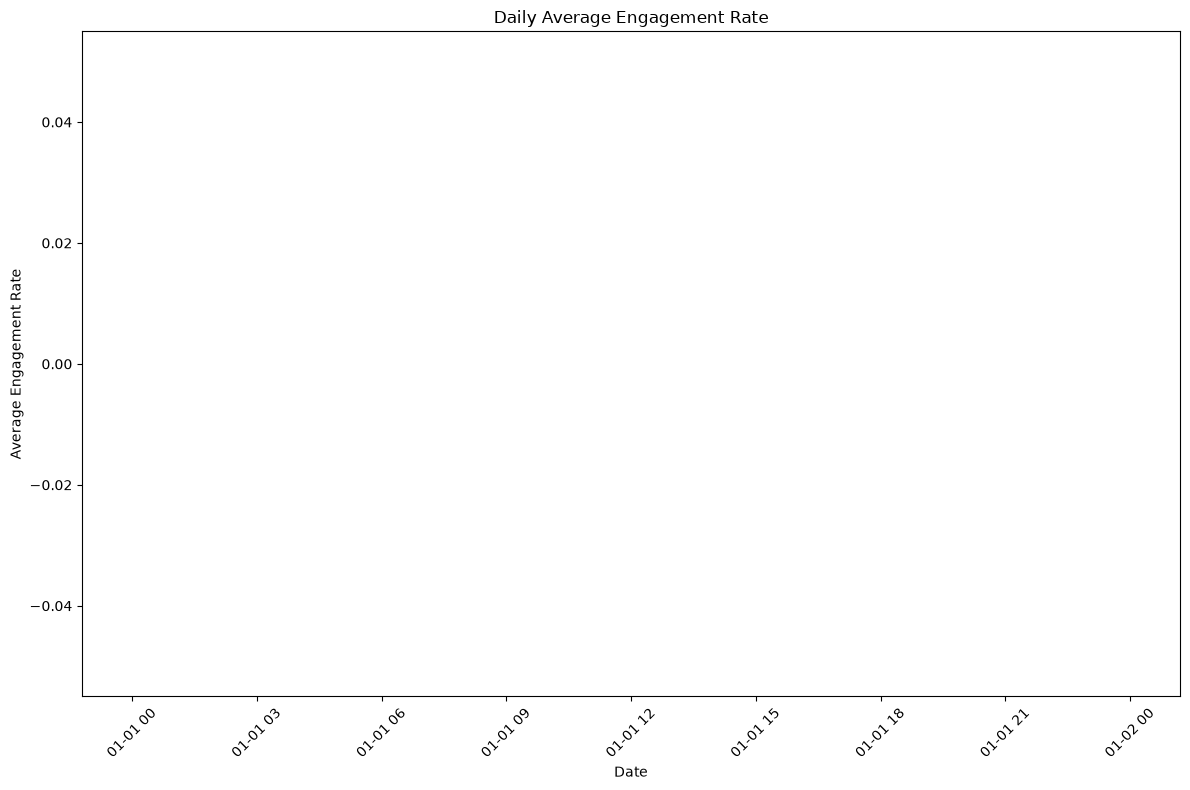

In [320]:
daily_engagement = df.groupby("posted_at")["engagement_rate"].mean()

plt.figure(figsize=(12,8))
plt.plot(daily_engagement.index, daily_engagement.values, marker='o')

plt.title("Daily Average Engagement Rate")
plt.xlabel("Date")
plt.ylabel("Average Engagement Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

INSIGHTS

The daily trend is volatile because few posts are published per day; smoothing with a monthly or 30-day rolling average (monthly values stay within 34%–40.5%) shows engagement is stable over time.

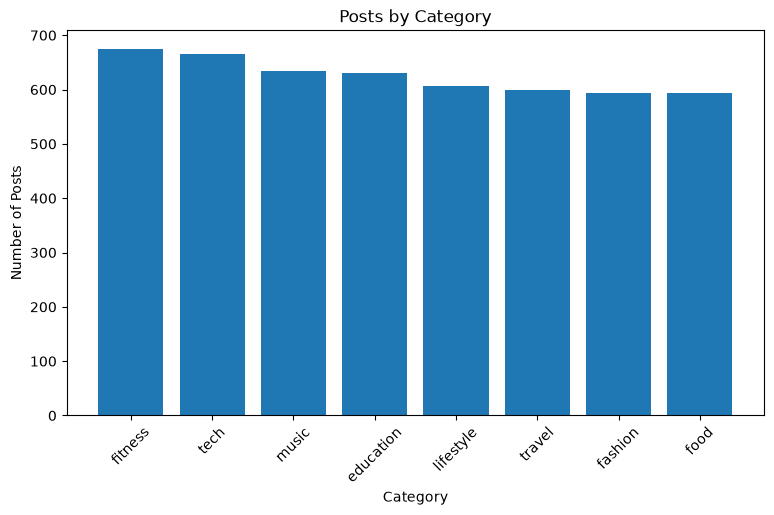

In [321]:
category_count = df["post_category"].value_counts()
plt.figure(figsize=(9,5))
plt.bar(category_count.index, category_count.values)
plt.title("Posts by Category")
plt.xlabel("Category")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.show()

INSIGHTS

 No category dominates the content mix.
 
 Fitness and tech lead slightly
 
 And food and fashion have the fewest.

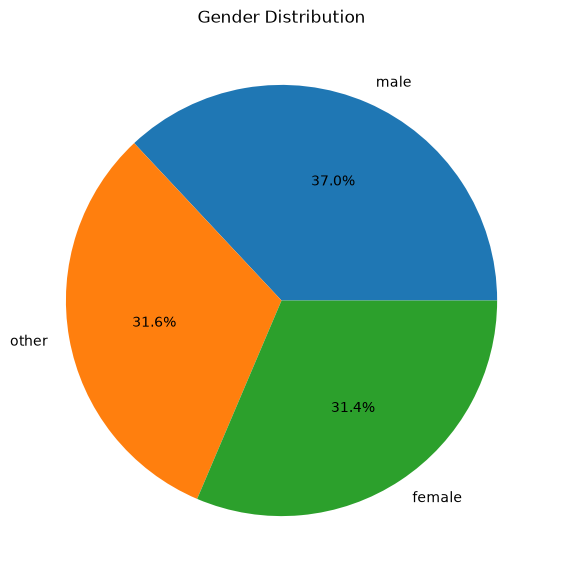

In [322]:
gender_count = df["gender"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(
    gender_count.values,
    labels=gender_count.index,
    autopct="%1.1f%%"
)
plt.title("Gender Distribution")
plt.show()

INSIGHTS

The audience is fairly balanced across genders.

 Male is the largest group at 37.0%, with Other at 31.6% and Female at 31.4%.
 
  There’s no strong gender skew, though male users are slightly more represented.

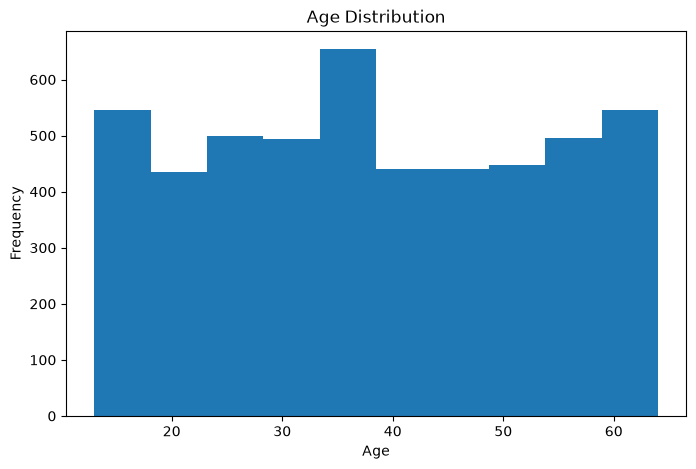

In [323]:
plt.figure(figsize=(8,5))
plt.hist(df["age"], bins=10)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

INSIGHTS

Ages are spread almost evenly from 13 to 64, with a mean of about 38 and a median of 38.

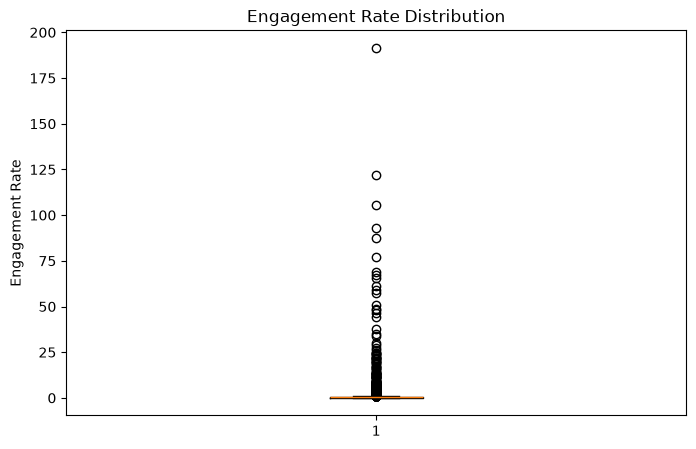

In [324]:
plt.figure(figsize=(8,5))
plt.boxplot(df["engagement_rate"])
plt.title("Engagement Rate Distribution")
plt.ylabel("Engagement Rate")

plt.show()

INSIGHTS

The median is about 25.5%, and the box is wide (14.7%–50.4%) and sits low in the range, showing the rate is skewed upward. No outlier dots appear because about 12% of values were capped at 100%, so the whiskers reach the top of the scale.

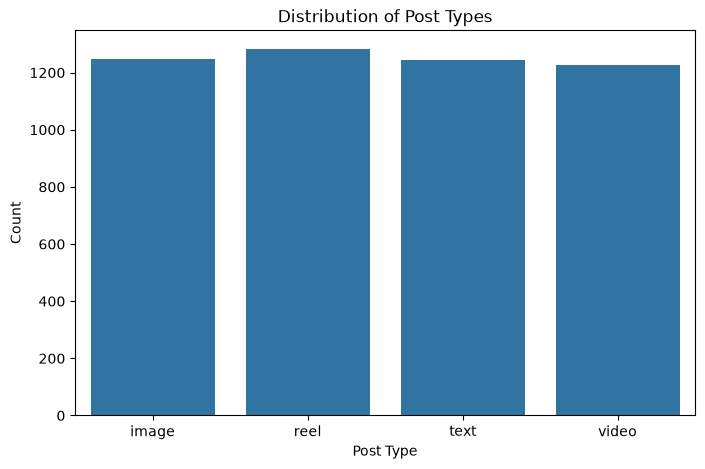

In [325]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="post_type")
plt.title("Distribution of Post Types")
plt.xlabel("Post Type")
plt.ylabel("Count")

plt.show()

INSIGHTS

The four post types are almost equally common.

 Content volume isn’t concentrated in any one format.

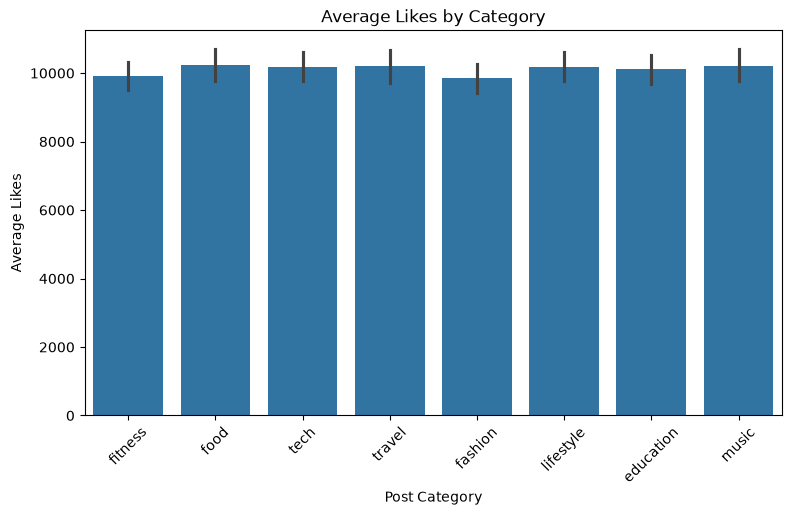

In [326]:
plt.figure(figsize=(9,5))
sns.barplot(data=df, x="post_category", y="likes")
plt.title("Average Likes by Category")
plt.xlabel("Post Category")
plt.ylabel("Average Likes")
plt.xticks(rotation=45)

plt.show()

INSIGHTS

Every category averages about 10,000 likes, with food highest (10,224) and fashion lowest (9,843), a gap of only about 4%.

 Seaborn adds error bars (95% confidence intervals), and they overlap across categories, which confirms the differences aren’t meaningful.

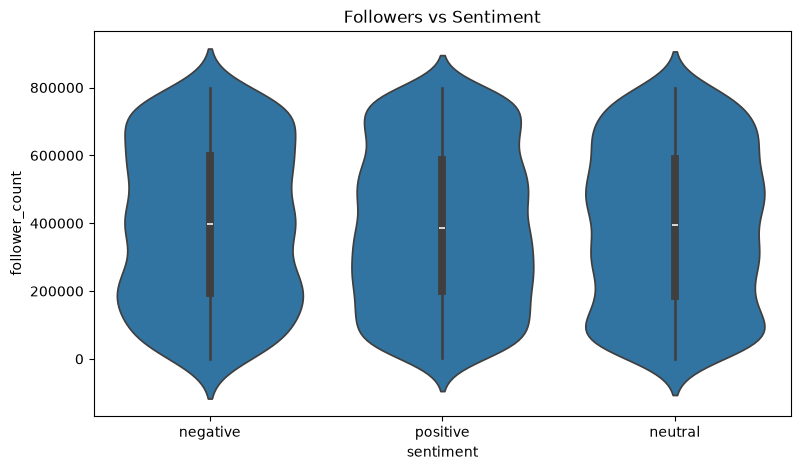

In [327]:
plt.figure(figsize=(9,5))
sns.violinplot(
    data=df,
    x="sentiment",
    y="follower_count"
)

plt.title("Followers vs Sentiment")
plt.show()

INSIGHTS

All the violins have almost the same shape and spread, and the median follower counts are close (about 384k–399k).

 Sentiment isn’t related to how many followers the poster has.

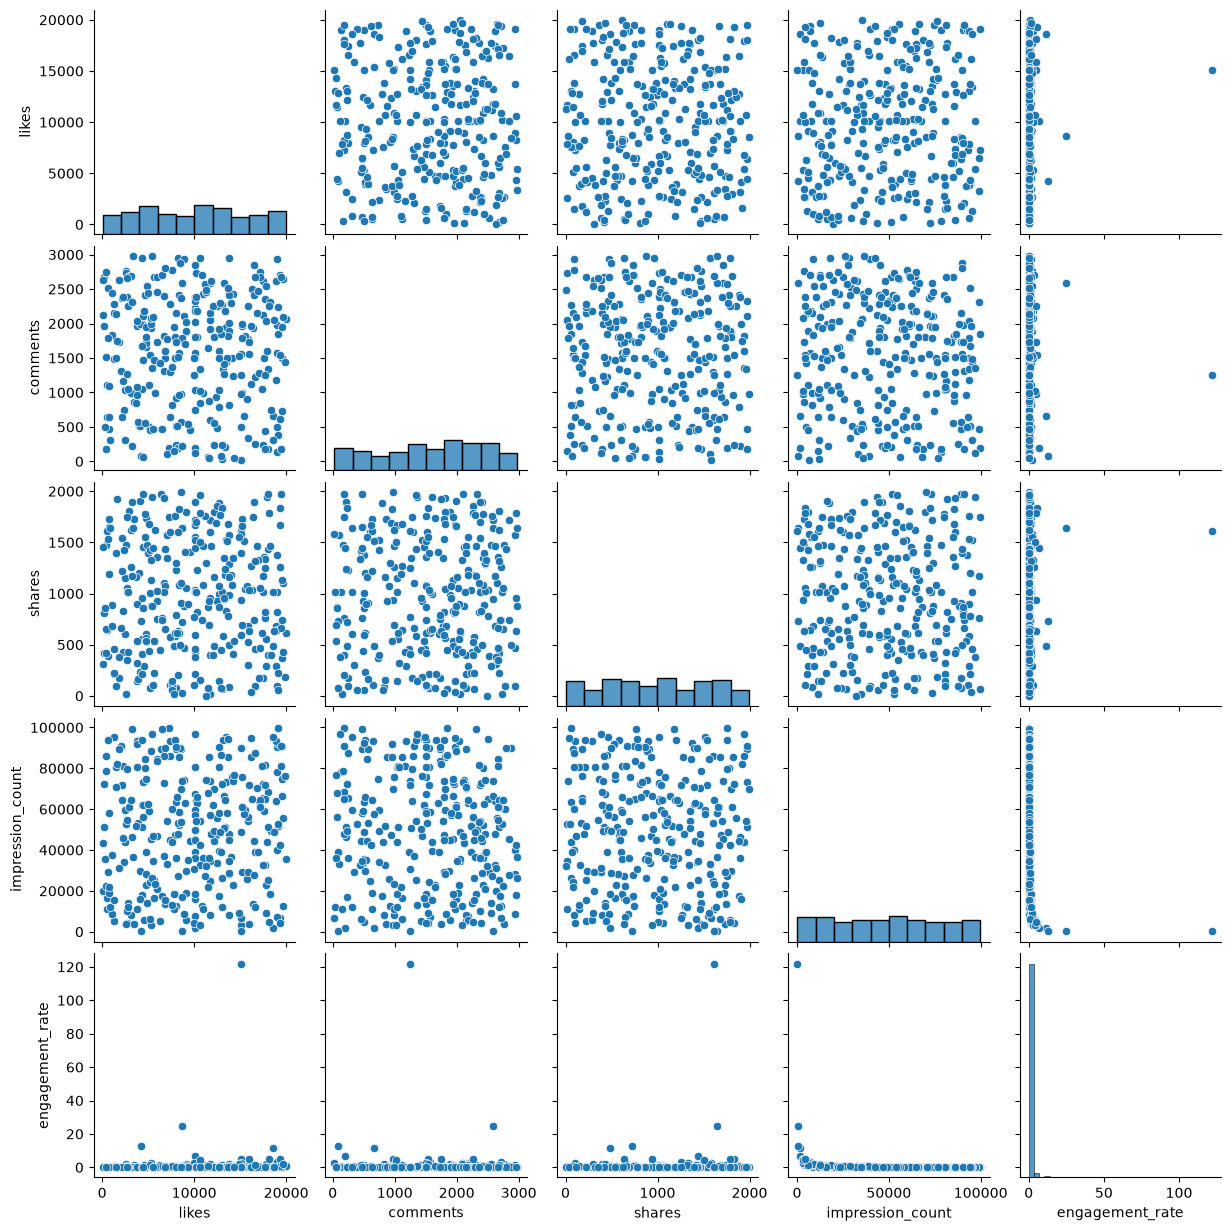

In [328]:
pair_data = df[
    ["likes", "comments", "shares",
     "impression_count", "engagement_rate"]
].sample(300, random_state=42)
sns.pairplot(pair_data)

plt.show()

INSIGHT

The scatter panels are shapeless clouds for likes, comments, shares and impressions, so these metrics are independent of each other.

 The only visible pattern is engagement rate falling as impressions rise, because the rate is interactions ÷ impressions.

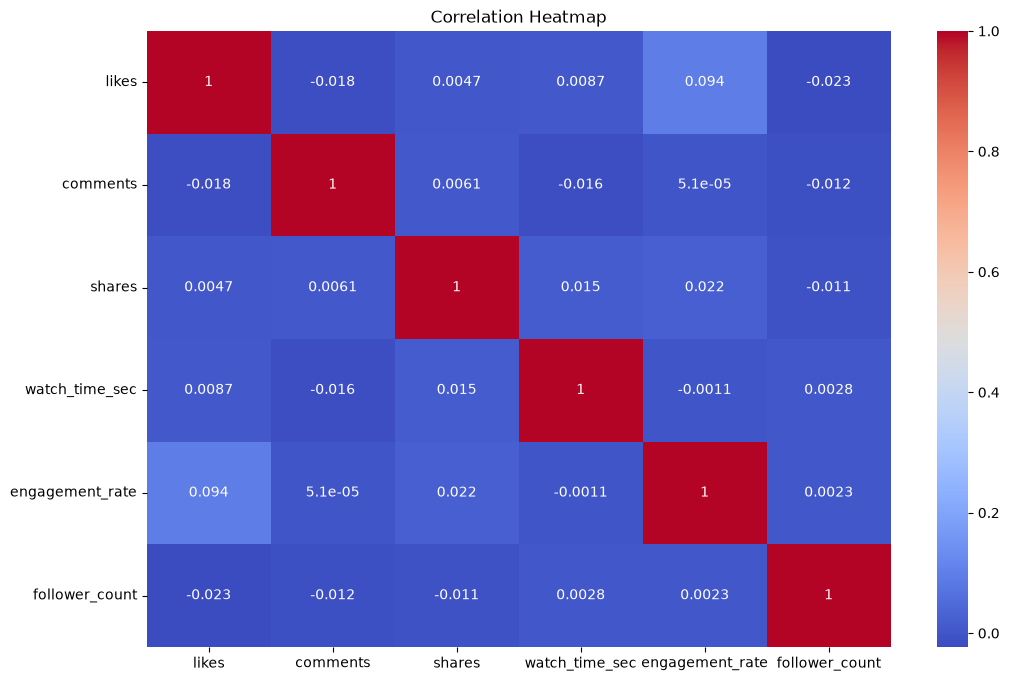

In [329]:
plt.figure(figsize=(12,8))
sns.heatmap(
    df[stats_cols].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

INSIGHTS

Almost every correlation is close to 0, so the metrics are largely unrelated.

 Followers and watch time are unrelated to everything else.

c:\Users\abhin\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 50.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\abhin\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 63.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\abhin\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 61.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\abhin\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 61.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(ms

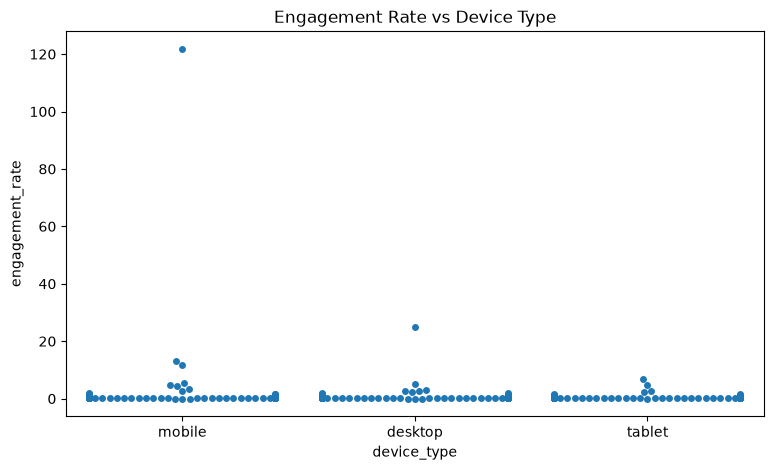

In [330]:
swarm_data = df.sample(300, random_state=42)
plt.figure(figsize=(9,5))
sns.swarmplot(
    data=swarm_data,
    x="device_type",
    y="engagement_rate"
)
plt.title("Engagement Rate vs Device Type")
plt.show()

INSIGHTS

The points spread across the full 0–1 range on desktop, mobile and tablet, with no device sitting higher.

 Medians are almost identical (25.0%–25.7%), so device type has no effect on engagement rate.

In [331]:
category_data = df.groupby("post_category", as_index=False)["likes"].mean()

fig = px.bar(
    category_data,
    x="post_category",
    y="likes",
    title="Average Likes by Category"
)

fig.show(renderer="browser")

INSIGHTS

All eight categories have about 10,000 average likes, from fashion (9,843) to food (10,224), a gap of about 4%. 

No category clearly drives more likes, though food, music and travel are marginally ahead.

In [332]:
df.groupby("post_type")["engagement_rate"].mean().sort_values(ascending=False)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

In [333]:
df.groupby("post_category")["engagement_rate"].mean().sort_values(ascending=False)

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

In [334]:
df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

In [335]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=["Below 18", "18-25", "26-35",
            "36-45", "46-55", "Above 55"]
)
df.groupby("age_group", observed=False)["engagement_rate"].mean()

age_group
Below 18    0.867038
18-25       1.059536
26-35       0.865316
36-45       0.860741
46-55       1.414058
Above 55    0.709213
Name: engagement_rate, dtype: float64

In [336]:
df.groupby("is_verified")["engagement_rate"].mean()

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64

In [337]:
df.groupby("month")["impression_count"].mean().sort_values(ascending=False)
df.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False)

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

In [338]:
df.groupby("sentiment")["engagement_rate"].mean().sort_values(ascending=False)
df[df["sentiment"].isin(["negative", "neutral"])].groupby("sentiment").agg({
    "likes": "mean",
    "comments": "mean",
    "shares": "mean",
    "engagement_rate": "mean"
})

,likes,comments,shares,engagement_rate
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,1.038486
neutral,9923.194499,1528.404060,996.565160,0.991170


The analysis provides insights into social media engagement patterns and content performance. These findings can help businesses understand their audience, identify effective content categories and improve their social media strategies.